# 05 — Correlations between all extracted quantities

One row per shot, with everything extracted so far:

| group | quantities |
|---|---|
| charge | `BCM_GUN` |
| laser | `laser_amp` (matched filter on `laser_scope`, notebook 03), `lab_laser_power` |
| pickups / klystron | `PGLA_drop` (notebook 02), flat-top mean of `PKI15A`, `PKI15P`, `PKR15A` |
| magnets | `DHG0130`, `SNH_110`, `SNI_120` |
| screen | `BTV_amplitude`, `BTV_intensity`, `BTV_mean_x/y`, `BTV_sigma_x/y` (notebook 04 — run it first) |
| screen, PCA | `PC1` … `PCn` image scores (notebook 04_1 — run it first) |

**Timing:** the devices are not all stored in the same row for the same shot. A lag scan (below) shows two groups:
- **A** — `BCM_GUN` and the BTV screen (classic parameters and PCA scores): same row
- **B** — laser scope, laser power meter, and the `SamplesFromTrigger` waveforms (pickups, klystron): one row **later**

So we shift group B by one row (`B[i + 1]` is paired with `A[i]`) and drop frozen laser-scope / camera shots.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
OUT_DIR = DATA_DIR.parent / "outputs"
files = sorted(DATA_DIR.glob("chunk_*.h5"))


def load(key):
    return np.concatenate([h5py.File(path, "r")[key][:] for path in files])


# diverging blue <-> red with a neutral grey midpoint (r = 0)
DIVERGING = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#cde2fb", "#f0efec", "#f6c6c5", "#e34948", "#9b1c1c"])
INK, MUTED, POINT = "#2b2b29", "#8a8985", "#2a78d6"

## Build the per-shot table (as recorded, before alignment)

In [2]:
# laser: matched-filter amplitude (same as notebook 03)
signal = load("laser_scope/signal")
t = h5py.File(files[0], "r")["laser_scope/times"][0]
clean = signal - signal[:, t < 5].mean(axis=1, keepdims=True)
template = clean.mean(axis=0) * ((t > 5.6) & (t < 39.8))
laser_frozen = np.r_[False, np.all(signal[1:] == signal[:-1], axis=1)]

pgla = load("PGLA/samples")[:, 0]
FLAT_TOP = slice(300, 640)

raw = pd.DataFrame({
    "BCM_GUN": load("BCM_GUN"),
    "laser_amp": clean @ template / (template @ template),
    "lab_laser_power": load("lab_laser_power"),
    "PGLA_drop": pgla[:, 631] - pgla[:, 636],
    "PKI15A": load("PKI15A/samples")[:, 0, FLAT_TOP].mean(axis=1),
    "PKI15P": load("PKI15P")[:, 0, FLAT_TOP].mean(axis=1),
    "PKR15A": load("PKR15A")[:, 0, FLAT_TOP].mean(axis=1),
    "DHG0130": load("DHG0130"),
    "SNH_110": load("SNH_110"),
    "SNI_120": load("SNI_120"),
})
btv = pd.read_csv(OUT_DIR / "btv0125_params.csv", index_col="shot")
for c in ["amplitude", "intensity", "mean_x", "mean_y", "sigma_x", "sigma_y"]:
    raw[f"BTV_{c}"] = btv[c].to_numpy()
pca = pd.read_csv(OUT_DIR / "btv0125_pca_scores.csv", index_col="shot")
raw[pca.columns] = pca.to_numpy()
CAMERA = [c for c in raw.columns if c.startswith(("BTV_", "PC"))]

GROUP_B = ["laser_amp", "lab_laser_power", "PGLA_drop", "PKI15A", "PKI15P", "PKR15A"]
print(raw.shape)
raw.describe().T[["mean", "std", "min", "max"]]

(2100, 26)


,mean,std,min,max
BCM_GUN,5.601164e+00,2.573954e-01,4.598656e+00,6.534118e+00
laser_amp,1.000000e+00,1.165401e-01,6.506316e-01,1.319553e+00
lab_laser_power,1.133703e-05,4.026604e-07,9.960369e-06,1.265950e-05
PGLA_drop,6.785249e+00,1.095484e+00,2.929688e+00,1.074219e+01
PKI15A,1.319270e+02,1.773529e-01,1.314597e+02,1.328441e+02
PKI15P,-2.511508e+01,1.165094e-01,-2.550264e+01,-2.470129e+01
PKR15A,-5.819482e+00,1.012019e-01,-6.166705e+00,-5.488856e+00
DHG0130,5.404380e-01,1.352988e-03,5.356620e-01,5.444428e-01
SNH_110,2.200036e+02,7.533383e-03,2.199840e+02,2.200260e+02
SNI_120,3.303041e+02,1.624616e-01,3.294778e+02,3.306681e+02


## Which row belongs to which shot? Lag scan against `BCM_GUN`

Shot-to-shot correlation (slow drift removed with a 51-shot rolling mean) between `X[i + lag]` and `BCM_GUN[i]`.
A peak at lag +1 means X is stored one row late.

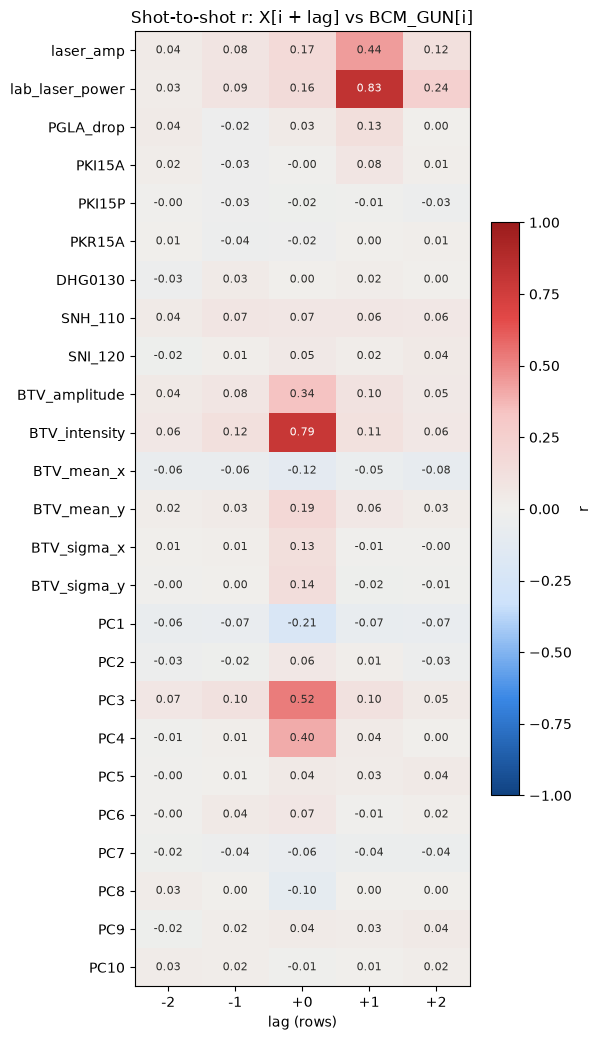

In [3]:
def detrend(x, k=51):
    x = pd.Series(np.asarray(x, float))
    return (x - x.rolling(k, center=True, min_periods=1).mean()).to_numpy()


LAGS = np.arange(-2, 3)
bcm_d = detrend(raw["BCM_GUN"])
lag_table = pd.DataFrame(
    {lag: [np.corrcoef(np.roll(detrend(raw[c]), -lag)[5:-5], bcm_d[5:-5])[0, 1] for c in raw.columns[1:]] for lag in LAGS},
    index=raw.columns[1:],
)

fig, ax = plt.subplots(figsize=(6, 0.36 * len(lag_table) + 1.5))
im = ax.imshow(lag_table, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
for (i, j), r in np.ndenumerate(lag_table.to_numpy()):
    ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(r) > 0.6 else INK)
ax.set_xticks(range(len(LAGS)), [f"{lag:+d}" for lag in LAGS])
ax.set_yticks(range(len(lag_table)), lag_table.index)
ax.set(xlabel="lag (rows)", title="Shot-to-shot r: X[i + lag] vs BCM_GUN[i]")
fig.colorbar(im, ax=ax, shrink=0.6, label="r")
fig.tight_layout()

## Align and clean

In [4]:
data = raw.copy()
data[GROUP_B] = raw[GROUP_B].shift(-1)          # row i now holds group B from row i + 1
laser_frozen_aligned = pd.Series(laser_frozen).shift(-1, fill_value=False).to_numpy()
btv_frozen = btv["frozen"].to_numpy()
complete = data[GROUP_B].notna().all(axis=1).to_numpy()  # the last row has no group-B partner

keep = ~laser_frozen_aligned & ~btv_frozen & complete
data = data[keep]
print(f"kept {keep.sum()} / {len(keep)} shots "
      f"(dropped {laser_frozen_aligned.sum()} frozen laser, {btv_frozen.sum()} frozen camera, {(~complete).sum()} lost to the shift)")

kept 1615 / 2100 shots (dropped 483 frozen laser, 1 frozen camera, 1 lost to the shift)


## Correlation matrices

- **left — overall**: includes the slow drift over the run (everything that drifts together correlates)
- **right — shot-to-shot**: slow drift removed (51-shot rolling mean), so only fast, shot-by-shot co-variation is left

Only the lower triangle is shown; |r| below ~0.07 is at the noise level for ~1600 shots.
Lines separate the groups: charge · laser · waveforms · magnets · screen (classic) · screen (PCA).

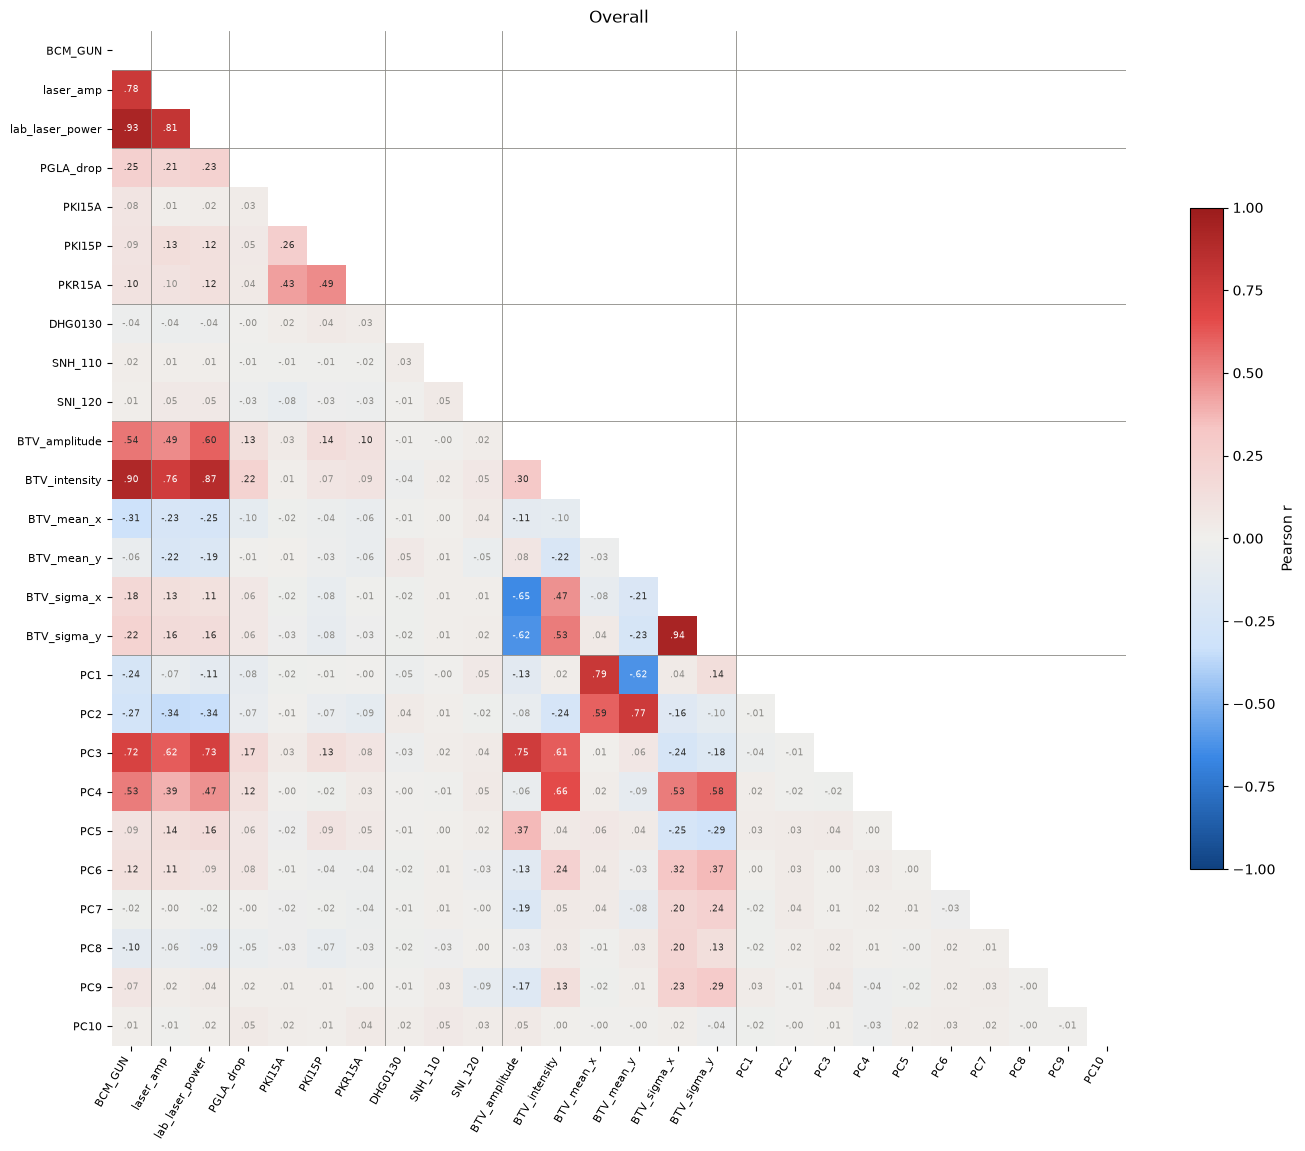

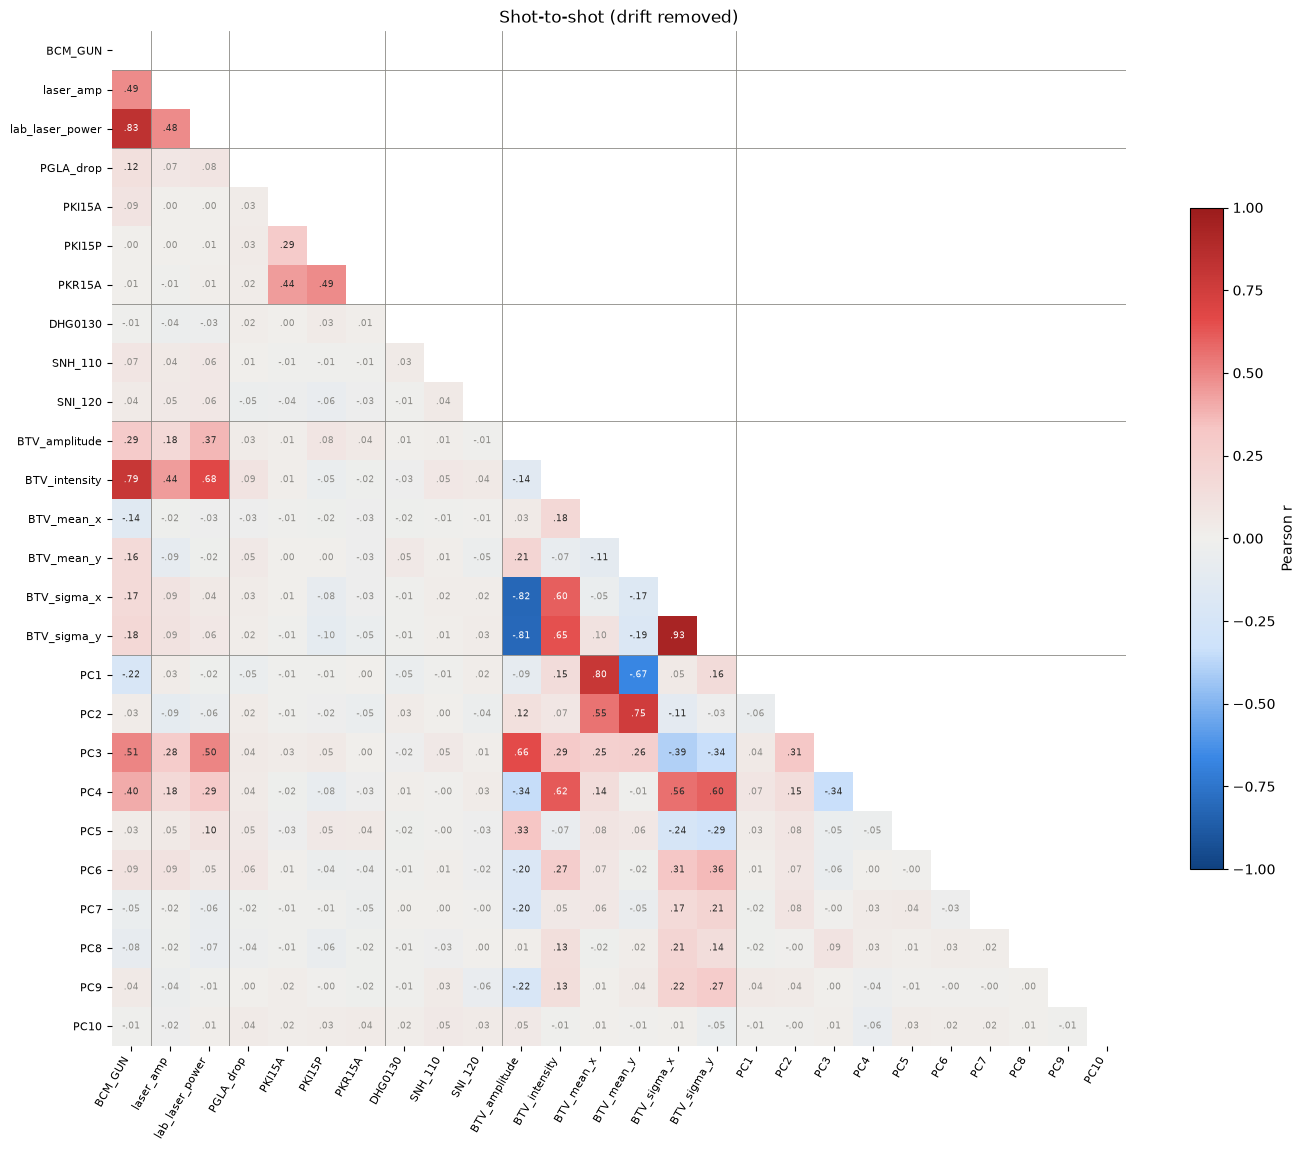

In [5]:
shot_to_shot = data.apply(detrend)
matrices = {"Overall": data.corr(), "Shot-to-shot (drift removed)": shot_to_shot.corr()}
names = data.columns
lower = np.tril(np.ones((len(names), len(names)), dtype=bool), k=-1)

group_edges = [names.get_loc(c) - 0.5 for c in ["laser_amp", "PGLA_drop", "DHG0130", "BTV_amplitude", "PC1"]]

for title, m in matrices.items():
    fig, ax = plt.subplots(figsize=(14, 12))
    shown = np.where(lower, m.to_numpy(), np.nan)
    im = ax.imshow(shown, cmap=DIVERGING, vmin=-1, vmax=1)
    for (i, j), r in np.ndenumerate(shown):
        if not np.isnan(r):
            ax.text(j, i, f"{r:.2f}".replace("0.", "."), ha="center", va="center", fontsize=6.5,
                    color="white" if abs(r) > 0.6 else (INK if abs(r) >= 0.1 else MUTED))
    for e in group_edges:
        ax.axhline(e, color=MUTED, lw=0.6)
        ax.axvline(e, color=MUTED, lw=0.6)
    ax.set_xticks(range(len(names)), names, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(names)), names, fontsize=8)
    ax.set_title(title)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.colorbar(im, ax=ax, shrink=0.6, label="Pearson r")
    fig.tight_layout()

## Strongest shot-to-shot relations

Pairs where **both** quantities come from the camera (classic parameters and PCA scores of the same images) are
left out here: they are the same picture measured two ways. They are still in the matrices above.

In [6]:
m = matrices["Shot-to-shot (drift removed)"]
pairs = (m.where(lower).stack().rename("r").reset_index()
         .assign(abs_r=lambda d: d["r"].abs()).sort_values("abs_r", ascending=False))
pairs = pairs[~(pairs["level_0"].isin(CAMERA) & pairs["level_1"].isin(CAMERA))]
pairs.head(12).drop(columns="abs_r").round(2)

,level_0,level_1,r
52,lab_laser_power,BCM_GUN,0.83
286,BTV_intensity,BCM_GUN,0.79
288,BTV_intensity,lab_laser_power,0.68
468,PC3,BCM_GUN,0.51
470,PC3,lab_laser_power,0.50
161,PKR15A,PKI15P,0.49
26,laser_amp,BCM_GUN,0.49
53,lab_laser_power,laser_amp,0.48
160,PKR15A,PKI15A,0.44
287,BTV_intensity,laser_amp,0.44


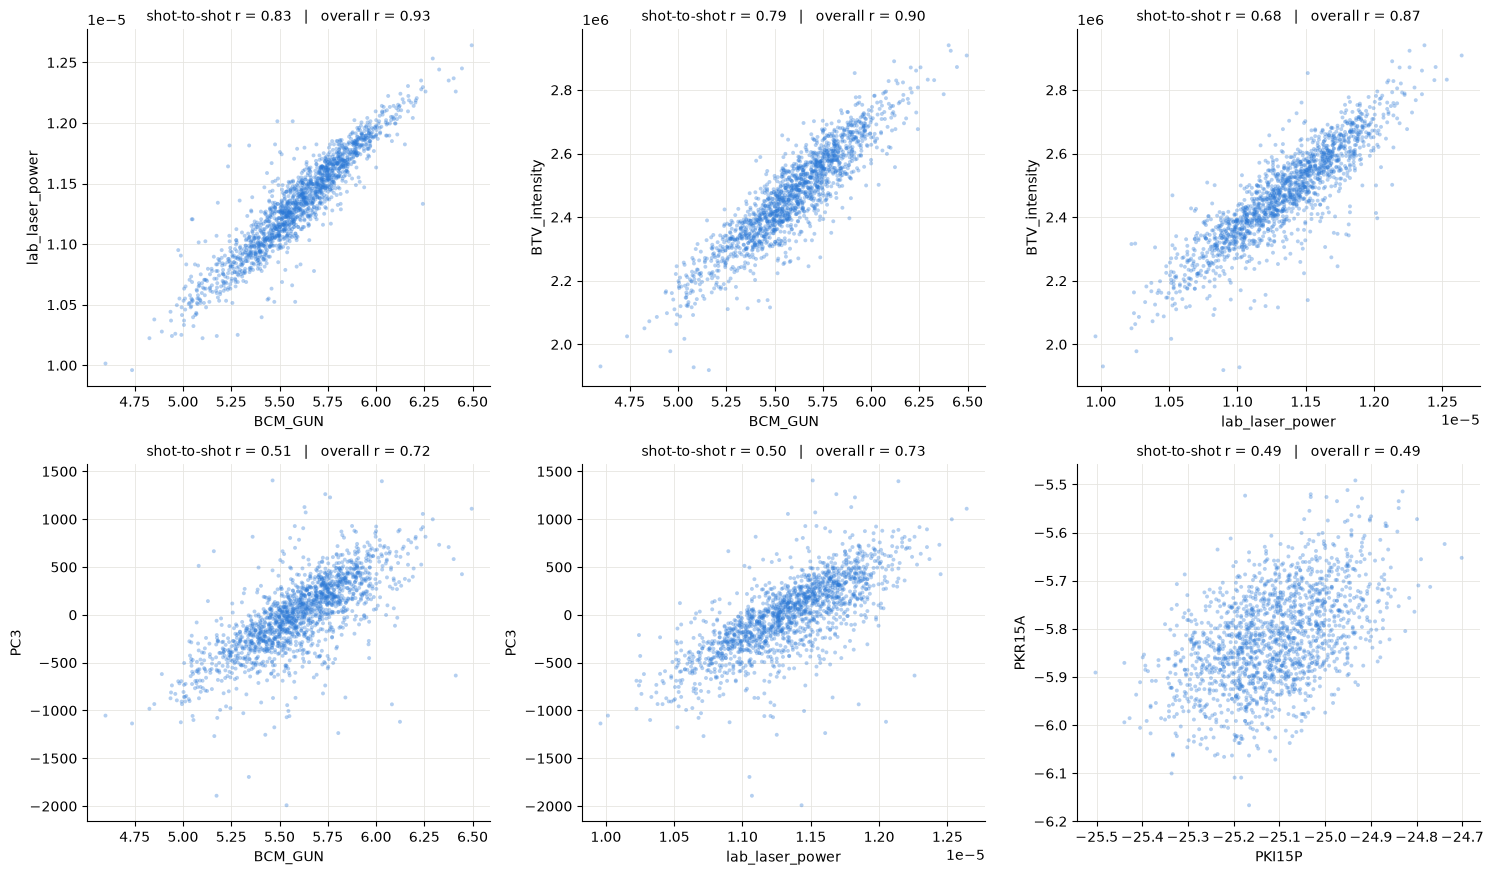

In [7]:
top = pairs.head(6)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (_, row) in zip(axes.ravel(), top.iterrows()):
    x, y = row["level_1"], row["level_0"]
    ax.scatter(data[x], data[y], s=8, color=POINT, alpha=0.35, edgecolors="none")
    r_all = matrices["Overall"].loc[y, x]
    ax.set(xlabel=x, ylabel=y, title=f"shot-to-shot r = {row['r']:.2f}   |   overall r = {r_all:.2f}")
    ax.title.set_fontsize(10)
    ax.grid(color="#e6e5e1", lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
fig.tight_layout()